In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

art = joblib.load("../artifacts/final_model.joblib")
model, FEATS, THR = art["model"], art["features"], art["threshold"]

test = pd.read_csv("s3://sagemaker-salesmesh-myra/processed/test.csv")
test["p"] = model.predict_proba(test[FEATS])[:, 1]
test["flag"] = (test["p"] >= THR).astype(int)

legit = test[test.fraud_bool == 0].reset_index(drop=True)
fraud = test[test.fraud_bool == 1].reset_index(drop=True)
P0 = test["flag"].mean()      # platform flag rate
print(f"Users: {len(test):,} | platform flag rate P0 = {P0:.4f}")

Users: 205,011 | platform flag rate P0 = 0.0539


In [2]:
def simulate(n_agents=200, n_bad=10, bad_fake_share=0.40,
             size_range=(50, 300), k=10, seed=0):
    rng = np.random.default_rng(seed)
    rows = []
    for a in range(n_agents):
        bad = a < n_bad
        n = int(rng.integers(size_range[0], size_range[1] + 1))
        if bad:
            n_fake = rng.binomial(n, bad_fake_share)
            idx_f = rng.integers(0, len(fraud), n_fake)
            idx_l = rng.integers(0, len(legit), n - n_fake)
            users = pd.concat([fraud.iloc[idx_f], legit.iloc[idx_l]])
        else:
            users = test.iloc[rng.integers(0, len(test), n)]
        flags = int(users["flag"].sum())
        smoothed = (flags + k * P0) / (n + k)
        rows.append({"agent": a, "type": "fraudulent" if bad else "honest",
                     "bad": int(bad), "n_users": n,
                     "fake_users": int(users["fraud_bool"].sum()),
                     "flags": flags, "flag_rate": flags / n,
                     "reputation": 100 * (1 - smoothed),
                     "reputation_simple": 100 * (1 - users["p"].mean())})
    return pd.DataFrame(rows)

Separation (AUC) — smoothed flag rate: 1.000 | simple mean prob: 1.000
Fraudulent agents in the bottom 10 by reputation: 10 of 10

Reputation range:
type                     fraudulent  honest
reputation        count        10.0   190.0
                  mean         84.0    94.5
                  std           3.3     1.7
                  min          79.8    88.9
                  25%          80.7    93.5
                  50%          84.5    94.6
                  75%          86.7    95.4
                  max          88.3    99.2
reputation_simple count        10.0   190.0
                  mean         98.1    99.0
                  std           0.2     0.1
                  min          97.8    98.6
                  25%          98.0    98.9
                  50%          98.0    99.0
                  75%          98.2    99.1
                  max          98.4    99.3


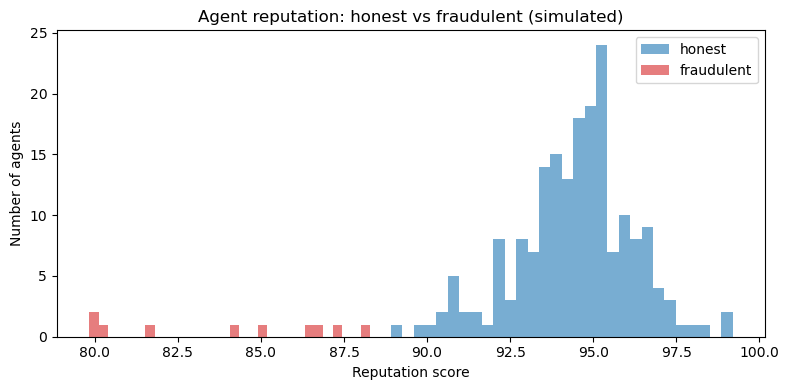

In [3]:
agents = simulate(seed=42)

auc_new = roc_auc_score(agents["bad"], -agents["reputation"])
auc_old = roc_auc_score(agents["bad"], -agents["reputation_simple"])
hits = agents.nsmallest(10, "reputation")["bad"].sum()

print(f"Separation (AUC) — smoothed flag rate: {auc_new:.3f} | simple mean prob: {auc_old:.3f}")
print(f"Fraudulent agents in the bottom 10 by reputation: {hits} of 10")
print("\nReputation range:")
print(agents.groupby("type")[["reputation", "reputation_simple"]].describe().T.round(1))

fig, ax = plt.subplots(figsize=(8, 4))
for t, c in [("honest", "tab:blue"), ("fraudulent", "tab:red")]:
    ax.hist(agents.loc[agents.type == t, "reputation"], bins=30, alpha=0.6, label=t, color=c)
ax.set(xlabel="Reputation score", ylabel="Number of agents",
       title="Agent reputation: honest vs fraudulent (simulated)")
ax.legend(); plt.tight_layout()
plt.savefig("../artifacts/agent_reputation_hist.png", dpi=150); plt.show()

In [4]:
rows = []
for share in [0.05, 0.10, 0.20, 0.40]:
    for size in [(10, 30), (50, 300)]:
        aucs, hits = [], []
        for seed in range(10):
            df = simulate(bad_fake_share=share, size_range=size, seed=seed)
            aucs.append(roc_auc_score(df["bad"], -df["reputation"]))
            hits.append(df.nsmallest(10, "reputation")["bad"].sum())
        rows.append({"fake share (bad agents)": share, "users per agent": f"{size[0]}–{size[1]}",
                     "mean AUC": round(np.mean(aucs), 3),
                     "bad agents in bottom 10 (of 10)": round(np.mean(hits), 1)})
sensitivity = pd.DataFrame(rows)
sensitivity

,fake share (bad agents),users per agent,mean AUC,bad agents in bottom 10 (of 10)
0,0.05,10–30,0.579,0.5
1,0.05,50–300,0.681,1.6
2,0.10,10–30,0.643,1.0
3,0.10,50–300,0.815,3.3
4,0.20,10–30,0.754,2.5
5,0.20,50–300,0.977,6.7
6,0.40,10–30,0.881,4.9
7,0.40,50–300,1.000,9.7


In [5]:
honest = agents.loc[agents.type == "honest", "reputation"]
watch = honest.quantile(0.10)
high = honest.quantile(0.02)
print(f"Proposed bands: Low risk >= {watch:.1f} | Watch {high:.1f}–{watch:.1f} | High risk < {high:.1f}")

agents["band"] = pd.cut(agents["reputation"], [-1, high, watch, 101],
                        labels=["High risk", "Watch", "Low risk"])
pd.crosstab(agents["type"], agents["band"])

Proposed bands: Low risk >= 92.2 | Watch 90.5–92.2 | High risk < 90.5


band,High risk,Watch,Low risk
type,,,
fraudulent,10,0,0
honest,4,15,171


In [6]:
agents.to_csv("../artifacts/agent_simulation.csv", index=False)
sensitivity.to_csv("../artifacts/agent_sensitivity.csv", index=False)
print({"P0": round(P0, 4), "k": 10, "watch_below": round(watch, 1), "high_below": round(high, 1)})

{'P0': 0.0539, 'k': 10, 'watch_below': 92.2, 'high_below': 90.5}
